In [3]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

con = duckdb.connect("../warehouse/olist.duckdb", read_only=True)
q = lambda sql: con.sql(sql).df()
FIG = "../reports/figures/"

q("SELECT count(*) AS orders, round(sum(order_value)) AS revenue FROM marts.fct_orders WHERE is_valid_sale")

,orders,revenue
0,98207,15735527.0


In [4]:
monthly = q("""
    WITH monthly AS (
        SELECT date_trunc('month', purchase_date) AS month,
               count(*)                           AS orders,
               sum(order_value)::DOUBLE           AS revenue,
               avg(order_value)::DOUBLE           AS avg_order_value
        FROM marts.fct_orders
        WHERE is_valid_sale
          AND purchase_date BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'
        GROUP BY 1
    )
    SELECT *,
           round(100 * (revenue / lag(revenue) OVER (ORDER BY month) - 1), 1) AS mom_growth_pct,
           sum(revenue) OVER (ORDER BY month)                               AS cumulative_revenue
    FROM monthly
    ORDER BY month
""")
monthly.round(1)

C:\Users\Admin\AppData\Local\Temp\ipykernel_43588\266518513.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  monthly.round(1)


,month,orders,revenue,avg_order_value,mom_growth_pct,cumulative_revenue
0,2017-01-01,787,136943.5,174.0,NaN,136943.5
1,2017-02-01,1718,283561.7,165.1,107.1,420505.2
2,2017-03-01,2617,425618.0,162.6,50.1,846123.1
3,2017-04-01,2377,405848.6,170.7,-4.6,1251971.7
4,2017-05-01,3640,582710.8,160.1,43.6,1834682.6
5,2017-06-01,3205,499652.2,155.9,-14.3,2334334.8
6,2017-07-01,3946,578753.7,146.7,15.8,2913088.5
7,2017-08-01,4272,661903.5,154.9,14.4,3574992.0
8,2017-09-01,4227,717102.7,169.6,8.3,4292094.8
9,2017-10-01,4547,764756.0,168.2,6.6,5056850.8


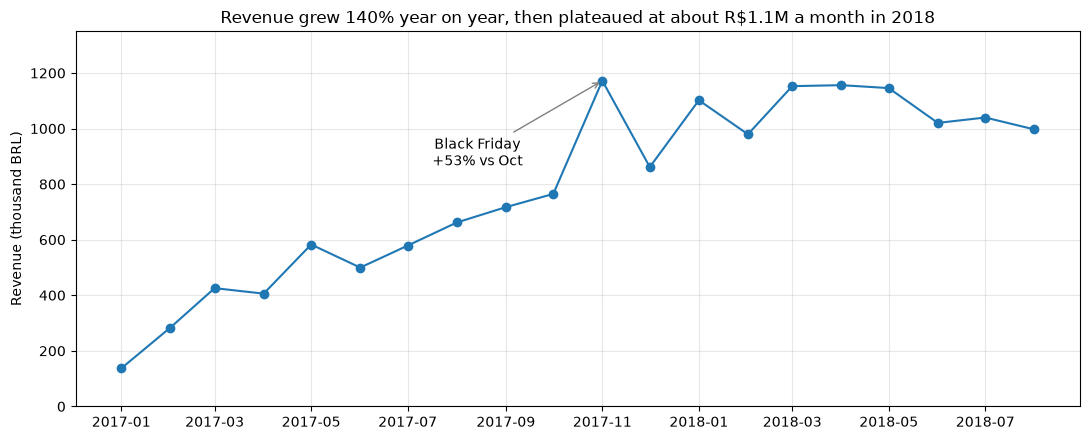

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly["month"], monthly["revenue"] / 1e3, marker="o")

bf = monthly.loc[monthly["month"] == pd.Timestamp("2017-11-01")].iloc[0]
ax.annotate("Black Friday\n+53% vs Oct", xy=(bf["month"], bf["revenue"] / 1e3),
            xytext=(-90, -40), textcoords="offset points", ha="center", va="top",
            arrowprops=dict(arrowstyle="->", color="grey"))

ax.set_title("Revenue grew 140% year on year, then plateaued at about R$1.1M a month in 2018")
ax.set_ylabel("Revenue (thousand BRL)")
ax.set_ylim(0, 1350)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG + "monthly_revenue.png", dpi=150)

## Q1: How fast is revenue growing?

**Revenue grew 140% year on year**, from R$3.57M in Jan–Aug 2017 to R$8.59M in Jan–Aug 2018 (R$15.7M in total over the 20 complete months).

- **Growth came from order volume, not basket size.** Monthly orders rose from 787 to over 7,000, while average order value stayed between R$147 and R$174 throughout.
- **Black Friday is the single biggest month:** November 2017 reached R$1.17M, 53% above October, before falling back 26.5% in December.
- **Growth stalled in 2018.** Monthly revenue held at R$1.0–1.16M, peaking in March–May and edging down from June. Finding the next growth lever is the key question for the business.

In [6]:
cats = q("""
    WITH cat AS (
        SELECT p.category,
               sum(i.price)::DOUBLE        AS revenue,
               count(DISTINCT i.order_id)  AS orders
        FROM marts.fct_order_items i
        JOIN marts.dim_products p USING (product_id)
        WHERE i.is_valid_sale
        GROUP BY 1
    )
    SELECT category, revenue, orders,
           round(100 * revenue / sum(revenue) OVER (), 1) AS share_pct,
           rank() OVER (ORDER BY revenue DESC)            AS revenue_rank
    FROM cat
    ORDER BY revenue DESC
    LIMIT 15
""")
cats

,category,revenue,orders,share_pct,revenue_rank
0,health_beauty,1255695.13,8800,9.3,1
1,watches_gifts,1198185.21,5604,8.9,2
2,bed_bath_table,1035964.06,9399,7.7,3
3,sports_leisure,979740.92,7673,7.3,4
4,computers_accessories,904322.02,6654,6.7,5
5,furniture_decor,727465.05,6425,5.4,6
6,housewares,626825.80,5847,4.6,7
7,cool_stuff,620770.49,3616,4.6,8
8,auto,586585.73,3872,4.3,9
9,garden_tools,481009.94,3505,3.6,10


In [7]:
growth = q("""
    SELECT p.category,
           sum(i.price) FILTER (WHERE i.purchase_date BETWEEN DATE '2017-01-01' AND DATE '2017-08-31')::DOUBLE AS rev_2017,
           sum(i.price) FILTER (WHERE i.purchase_date BETWEEN DATE '2018-01-01' AND DATE '2018-08-31')::DOUBLE AS rev_2018,
           round(100 * (rev_2018 / rev_2017 - 1), 1) AS growth_pct
    FROM marts.fct_order_items i
    JOIN marts.dim_products p USING (product_id)
    WHERE i.is_valid_sale
    GROUP BY 1
    HAVING rev_2017 > 20000
    ORDER BY growth_pct DESC
""")
growth

,category,rev_2017,rev_2018,growth_pct
0,baby,70328.57,256086.70,264.1
1,stationery,37276.56,135468.72,263.4
2,watches_gifts,206284.44,708305.95,243.4
3,electronics,29614.23,101000.39,241.1
4,health_beauty,247457.95,770002.81,211.2
5,housewares,131132.61,397688.06,203.3
6,telephony,60745.02,179751.54,195.9
7,musical_instruments,37431.40,107746.08,187.8
8,auto,128278.06,346632.44,170.2
9,pet_shop,49750.29,128053.24,157.4


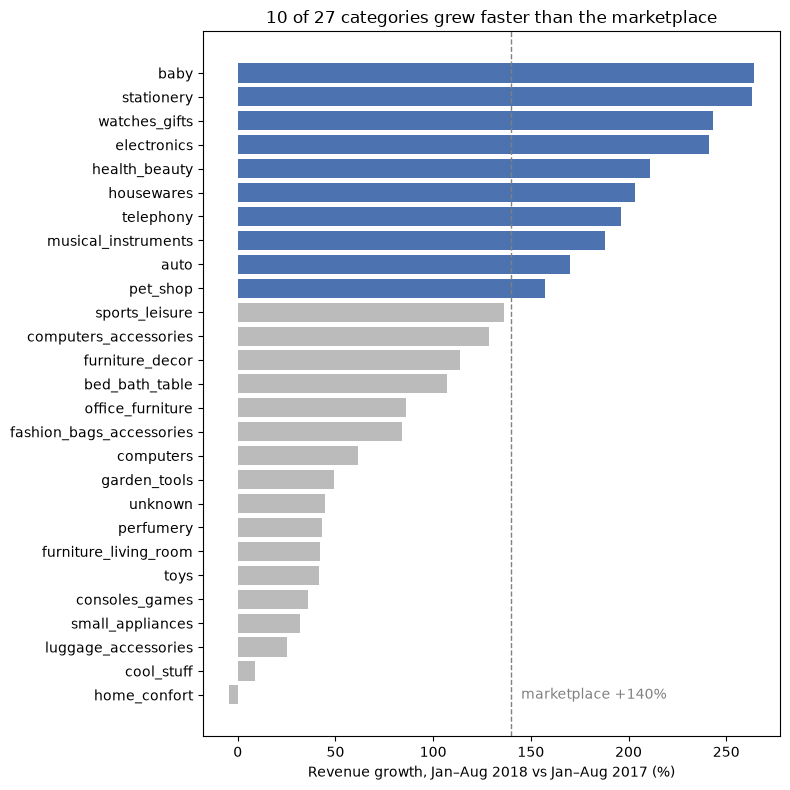

In [8]:
g = growth.sort_values("growth_pct")
colors = ["#4C72B0" if v >= 140 else "#BBBBBB" for v in g["growth_pct"]]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(g["category"], g["growth_pct"], color=colors)
ax.axvline(140, ls="--", color="grey", lw=1)
ax.text(145, 0, "marketplace +140%", va="center", color="grey")
ax.set_xlabel("Revenue growth, Jan–Aug 2018 vs Jan–Aug 2017 (%)")
ax.set_title("10 of 27 categories grew faster than the marketplace")
fig.tight_layout()
fig.savefig(FIG + "category_growth.png", dpi=150)

## Q1 (continued): Which categories drive revenue?

**Revenue is spread across many categories.** The top 5 (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories) generate 39.9% of item revenue, and the top 15 generate 76.3%.

- **Health & beauty is the largest category** (R$1.26M, 9.3% of revenue).
- **Watches & gifts earns more per order:** second by revenue from only 5,604 orders, about R$214 per order, against R$110 for bed_bath_table, which has the most orders (9,399).

**Growth (Jan–Aug 2018 vs Jan–Aug 2017, categories with over R$20k in 2017):**

- 10 of 27 categories grew faster than the marketplace's 140%. The fastest were baby (+264%), stationery (+263%) and watches_gifts (+243%).
- **The two largest categories are also among the fastest growing:** watches_gifts (+243%) and health_beauty (+211%).
- **Some established categories are losing share:** bed_bath_table (+107%), garden_tools (+49%), toys (+42%) and cool_stuff (+9%) all grew slower than the marketplace. Home_confort was the only category to shrink (−4.5%).

**Implication:** marketing budget should favour watches_gifts and health_beauty, which are both large and fast-growing, while the slowdown in bed_bath_table, the highest-volume category, is worth investigating.

In [9]:
ret = q("""
    WITH orders AS (
        SELECT customer_unique_id,
               date_trunc('month', purchase_date) AS order_month
        FROM marts.fct_orders
        WHERE is_valid_sale
    ),
    cohorts AS (
        SELECT customer_unique_id, min(order_month) AS cohort_month
        FROM orders
        GROUP BY 1
    ),
    activity AS (
        SELECT c.cohort_month,
               date_diff('month', c.cohort_month, o.order_month) AS months_since_first,
               count(DISTINCT o.customer_unique_id)              AS customers
        FROM orders o
        JOIN cohorts c USING (customer_unique_id)
        GROUP BY 1, 2
    )
    SELECT cohort_month,
           months_since_first,
           customers,
           round(100.0 * customers / first_value(customers) OVER (
               PARTITION BY cohort_month ORDER BY months_since_first), 2) AS retention_pct
    FROM activity
    WHERE cohort_month BETWEEN DATE '2017-01-01' AND DATE '2018-02-01'
    ORDER BY 1, 2
""")
ret.head(15)

,cohort_month,months_since_first,customers,retention_pct
0,2017-01-01,0,752,100.00
1,2017-01-01,1,3,0.40
2,2017-01-01,2,2,0.27
3,2017-01-01,3,1,0.13
4,2017-01-01,4,3,0.40
5,2017-01-01,5,1,0.13
6,2017-01-01,6,3,0.40
7,2017-01-01,7,1,0.13
8,2017-01-01,8,1,0.13
9,2017-01-01,10,3,0.40


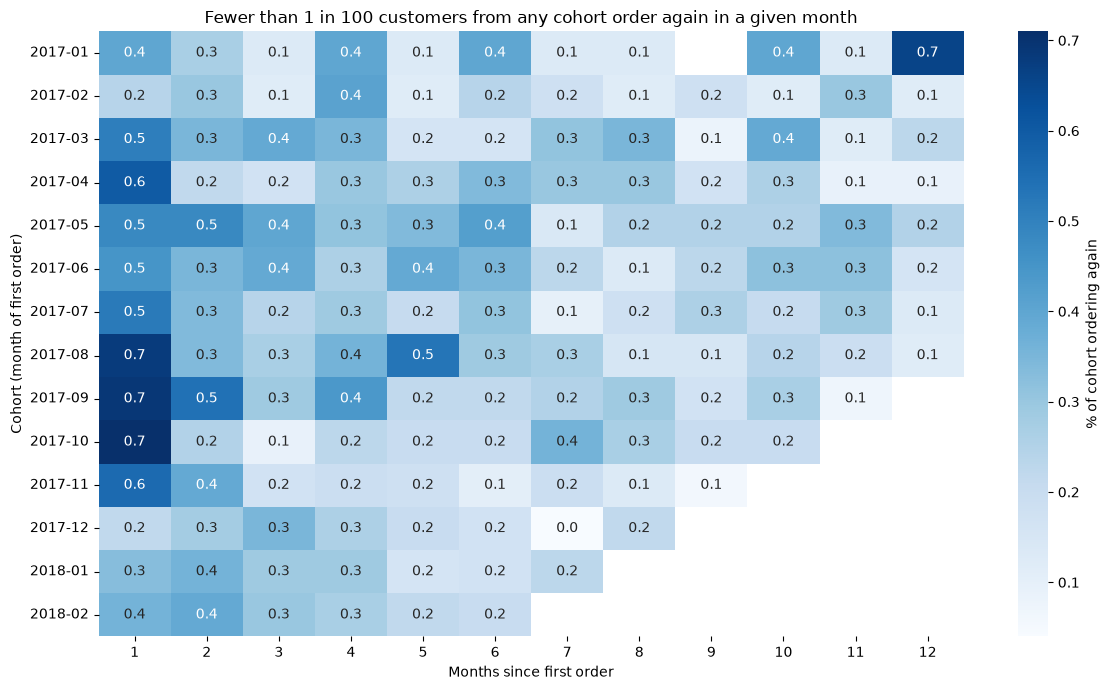

In [10]:
pivot = ret.pivot(index="cohort_month", columns="months_since_first", values="retention_pct")
pivot.index = pd.to_datetime(pivot.index).strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(pivot.loc[:, 1:12], annot=True, fmt=".1f", cmap="Blues",
            cbar_kws={"label": "% of cohort ordering again"}, ax=ax)
ax.set_xlabel("Months since first order")
ax.set_ylabel("Cohort (month of first order)")
ax.set_title("Fewer than 1 in 100 customers from any cohort order again in a given month")
fig.tight_layout()
fig.savefig(FIG + "cohort_retention.png", dpi=150)

q("""
    WITH first_orders AS (
        SELECT customer_unique_id, min(purchase_date) AS first_date
        FROM marts.fct_orders
        WHERE is_valid_sale
        GROUP BY 1
    ),
    reorders AS (
        SELECT f.customer_unique_id,
               count(o.order_id) > 0 AS reordered
        FROM first_orders f
        LEFT JOIN marts.fct_orders o
          ON  o.customer_unique_id = f.customer_unique_id
          AND o.is_valid_sale
          AND o.purchase_date >  f.first_date
          AND o.purchase_date <= f.first_date + INTERVAL 90 DAY
        WHERE f.first_date <= DATE '2018-05-31'
        GROUP BY 1
    )
    SELECT count(*)                                AS customers,
           sum(reordered::INT)                     AS reordered,
           round(100.0 * avg(reordered::INT), 2)   AS pct_reorder_within_90_days
    FROM reorders
""")

## Q2: Do customers come back?

**Almost never.** Only **1.3% of customers (1,002 of 76,845) placed a second order within 90 days** of their first. Over the whole dataset, 96.9% of customers ordered only once.

- **Every cohort behaves the same way:** in any month after the first purchase, fewer than 1% of a cohort orders again. Month 1 is the strongest (0.2–0.7%), after which repeat rates settle at 0.1–0.3%.
- **Newer customers are not more loyal.** The Dec 2017 to Feb 2018 cohorts returned at 0.2–0.4% in month 1, against 0.5–0.7% for the Aug–Oct 2017 cohorts, so the growth spurt brought in customers who were, if anything, less likely to return.

**Implication:** Olist's growth comes entirely from acquiring new customers. Even a small improvement in repeat purchasing, for example lifting the 90-day reorder rate from 1.3% to 3%, would add revenue without extra acquisition cost. This makes retention the biggest untapped lever, and links to Q4: unhappy first experiences, such as late deliveries, are a likely reason customers don't come back.

In [11]:
dv = q("""
    SELECT CASE
             WHEN delay_days <= -10 THEN '10+ days early'
             WHEN delay_days <= -1  THEN '1-9 days early'
             WHEN delay_days = 0    THEN 'On the day'
             WHEN delay_days <= 7   THEN '1-7 days late'
             ELSE '8+ days late'
           END                                              AS delivery_vs_promise,
           count(*)                                         AS orders,
           round(avg(review_score), 2)                      AS avg_review,
           round(100.0 * avg(is_negative_review::INT), 1)   AS pct_negative
    FROM marts.fct_orders
    WHERE order_status = 'delivered'
      AND delay_days IS NOT NULL
      AND review_score IS NOT NULL
    GROUP BY 1
    ORDER BY min(delay_days)
""")
dv

,delivery_vs_promise,orders,avg_review,pct_negative
0,10+ days early,61523,4.32,8.9
1,1-9 days early,26640,4.23,10.0
2,On the day,1280,4.03,12.4
3,1-7 days late,3600,2.71,49.4
4,8+ days late,2781,1.70,79.3


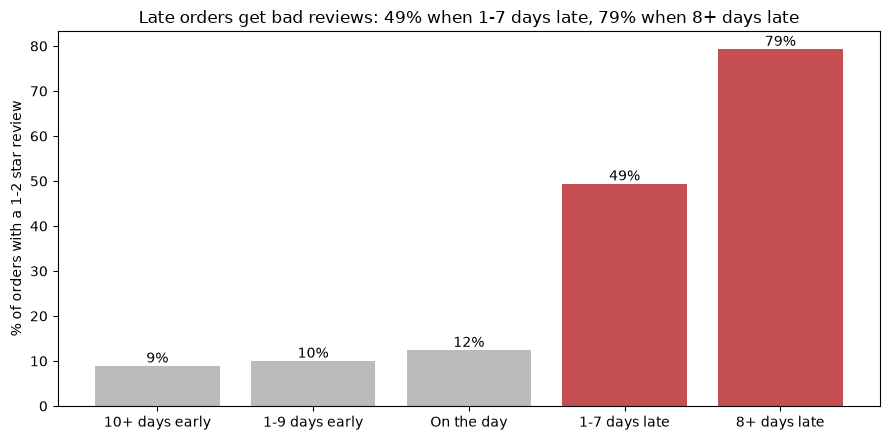

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#BBBBBB", "#BBBBBB", "#BBBBBB", "#C44E52", "#C44E52"]
bars = ax.bar(dv["delivery_vs_promise"], dv["pct_negative"], color=colors)
ax.bar_label(bars, fmt="%.0f%%")
ax.set_ylabel("% of orders with a 1-2 star review")
ax.set_title("Late orders get bad reviews: 49% when 1-7 days late, 79% when 8+ days late")
fig.tight_layout()
fig.savefig(FIG + "late_vs_reviews.png", dpi=150)

In [14]:
q("""
    SELECT count(*)                                         AS delivered_orders,
           round(100.0 * avg(is_late::INT), 1)              AS pct_late,
           round(avg(delivery_days), 1)                     AS avg_delivery_days,
           round(avg(promised_days), 1)                     AS avg_promised_days
    FROM marts.fct_orders
    WHERE order_status = 'delivered' AND delay_days IS NOT NULL
""")

,delivered_orders,pct_late,avg_delivery_days,avg_promised_days
0,96470,6.8,12.5,24.4


## Q4: Does late delivery hurt satisfaction?

**Yes, sharply.** Orders that arrive on or before the promised date get a 1–2 star review about 10% of the time. That jumps to **49% when an order is 1–7 days late and 79% when it is 8+ days late**, with average scores falling from 4.2 to 2.7 and 1.7.

- **Late orders are 6.7% of reviewed orders (6,381 of 95,824) but cause about a third of all bad reviews** (roughly 4,000 of 12,300).
- **Delivery promises are heavily padded.** Delivered orders took 12.5 days on average against a promised 24.4 days, and 64% arrived 10 or more days early. Despite this buffer, 6.8% of orders still arrived late.

**Implication:** preventing late deliveries, or contacting affected customers before they review, is the most direct way to reduce bad reviews. Because delay is so predictive, it is the foundation of the at-risk order model in Phase 6. Combined with Q2, it also suggests late deliveries are one reason so few customers return.

In [15]:
curve = q("""
    WITH seller_rev AS (
        SELECT seller_id, sum(price)::DOUBLE AS revenue
        FROM marts.fct_order_items
        WHERE is_valid_sale
        GROUP BY 1
    )
    SELECT row_number() OVER (ORDER BY revenue DESC) AS seller_rank,
           count(*) OVER ()                          AS n_sellers,
           sum(revenue) OVER (ORDER BY revenue DESC
                              ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
             / sum(revenue) OVER ()                  AS cum_share
    FROM seller_rev
    ORDER BY seller_rank
""")

for target in (0.5, 0.8):
    k = int(curve.loc[curve["cum_share"] >= target, "seller_rank"].iloc[0])
    print(f"{k} sellers ({k / len(curve):.1%}) generate {target:.0%} of revenue")

129 sellers (4.2%) generate 50% of revenue
540 sellers (17.7%) generate 80% of revenue


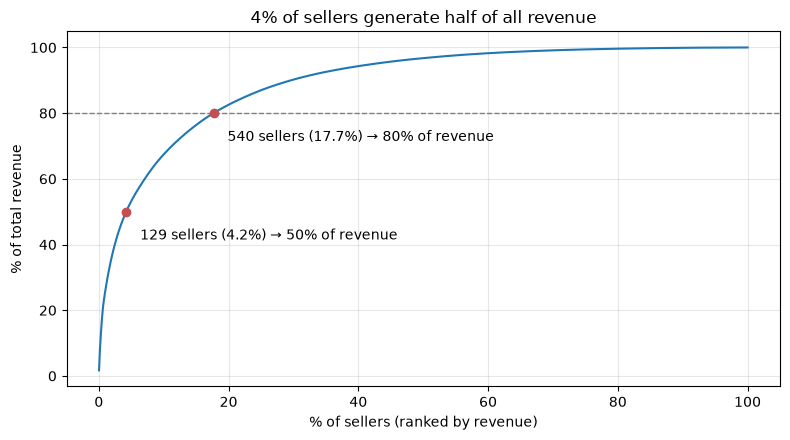

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(100 * curve["seller_rank"] / curve["n_sellers"], 100 * curve["cum_share"])
ax.axhline(80, ls="--", color="grey", lw=1)

for target in (0.5, 0.8):
    k = int(curve.loc[curve["cum_share"] >= target, "seller_rank"].iloc[0])
    x = 100 * k / len(curve)
    ax.plot(x, 100 * target, "o", color="#C44E52")
    ax.annotate(f"{k} sellers ({x:.1f}%) → {target:.0%} of revenue",
                xy=(x, 100 * target), xytext=(10, -20), textcoords="offset points")

ax.set_xlabel("% of sellers (ranked by revenue)")
ax.set_ylabel("% of total revenue")
ax.set_title("4% of sellers generate half of all revenue")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG + "seller_pareto.png", dpi=150)